# Inventory Compass — Full ML Pipeline

**Goal:** Retail demand forecasting using classical ML on a synthetic retail dataset.

**Pipeline:**
1. Load & Inspect Data
2. Data Cleaning & Preprocessing
3. Exploratory Data Analysis
4. Feature Engineering (no-leakage lag/rolling features)
5. Temporal Train / Validation / Test Split (70 / 15 / 15 %)
6. Baseline Models (Naive, Seasonal Naive)
7. ML Models: LinearRegression, RandomForest, HistGradientBoosting, XGBoost
8. Evaluate & Compare
9. Save Best Model + Metadata
10. Download Helper

> **Target variable:** `Units Sold` (daily sales per Store-Product)  \
> **Forecast horizon:** Next-day demand (t+1), using only information available through day t


## 0. Imports & Setup

In [1]:
import warnings; warnings.filterwarnings("ignore")
import time, json, math, os, zipfile
from pathlib import Path
from datetime import datetime

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor, HistGradientBoostingRegressor
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import mean_absolute_error, mean_squared_error
from xgboost import XGBRegressor

# ── Reproducibility ──────────────────────────────────────────────────────────
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

# ── Paths (notebook lives in backend/notebooks/) ─────────────────────────────
BACKEND_DIR   = Path(os.path.abspath(".."))
RAW_CSV       = BACKEND_DIR / "data" / "raw"  / "retail_store_inventory.csv"
PROCESSED_CSV = BACKEND_DIR / "data" / "processed" / "clean_inventory.csv"
MODELS_DIR    = BACKEND_DIR / "models"
REPORTS_DIR   = BACKEND_DIR / "reports"
for d in (MODELS_DIR, REPORTS_DIR, PROCESSED_CSV.parent):
    d.mkdir(parents=True, exist_ok=True)

# ── Plot style ───────────────────────────────────────────────────────────────
plt.style.use("seaborn-v0_8-whitegrid")
sns.set_palette("tab10")
plt.rcParams.update({"figure.dpi": 110, "figure.figsize": (12, 4)})

import sklearn, xgboost
print("Backend dir :", BACKEND_DIR)
print("Raw CSV     :", RAW_CSV.exists(), RAW_CSV)
print("Pandas      :", pd.__version__)
print("Scikit-learn:", sklearn.__version__)
print("XGBoost     :", xgboost.__version__)


Backend dir : C:\Projects\Inventory-compass\backend
Raw CSV     : True C:\Projects\Inventory-compass\backend\data\raw\retail_store_inventory.csv
Pandas      : 2.3.3
Scikit-learn: 1.7.2
XGBoost     : 3.2.0


## 1. Load & Inspect Data

In [2]:
df_raw = pd.read_csv(RAW_CSV)

# Strip whitespace from column names and all string values
df_raw.columns = df_raw.columns.str.strip()
for col in df_raw.select_dtypes("object").columns:
    df_raw[col] = df_raw[col].str.strip()

print(f"Shape: {df_raw.shape}")
print(f"Columns: {df_raw.columns.tolist()}")
df_raw.head(3)


Shape: (73100, 15)
Columns: ['Date', 'Store ID', 'Product ID', 'Category', 'Region', 'Inventory Level', 'Units Sold', 'Units Ordered', 'Demand Forecast', 'Price', 'Discount', 'Weather Condition', 'Holiday/Promotion', 'Competitor Pricing', 'Seasonality']


,Date,Store ID,Product ID,Category,Region,Inventory Level,Units Sold,Units Ordered,Demand Forecast,Price,Discount,Weather Condition,Holiday/Promotion,Competitor Pricing,Seasonality
0,2022-01-01,S001,P0001,Groceries,North,231,127,55,135.47,33.50,20,Rainy,0,29.69,Autumn
1,2022-01-01,S001,P0002,Toys,South,204,150,66,144.04,63.01,20,Sunny,0,66.16,Autumn
2,2022-01-01,S001,P0003,Toys,West,102,65,51,74.02,27.99,10,Sunny,1,31.32,Summer


In [3]:
print("=== Missing Values ===")
print(df_raw.isnull().sum())
print()
print("Stores   :", sorted(df_raw["Store ID"].unique()))
print("Products :", df_raw["Product ID"].nunique(), "unique")
print("Dates    :", df_raw["Date"].min(), "->", df_raw["Date"].max())
print()
print("Units Sold:")
print(df_raw["Units Sold"].describe())
print()
print(f"Zero sales rows              : {(df_raw['Units Sold']==0).sum()}")
print(f"Negative Demand Forecast rows: {(df_raw['Demand Forecast']<0).sum()}")
print()
dup = df_raw.duplicated(subset=["Store ID","Product ID","Date"]).sum()
sp_c = df_raw.groupby(["Store ID","Product ID"]).size()
print(f"Duplicate Store-Product-Date rows: {dup}")
print(f"Rows per Store-Product: min={sp_c.min()}, max={sp_c.max()}, balanced={sp_c.min()==sp_c.max()}")


=== Missing Values ===
Date                  0
Store ID              0
Product ID            0
Category              0
Region                0
Inventory Level       0
Units Sold            0
Units Ordered         0
Demand Forecast       0
Price                 0
Discount              0
Weather Condition     0
Holiday/Promotion     0
Competitor Pricing    0
Seasonality           0
dtype: int64

Stores   : ['S001', 'S002', 'S003', 'S004', 'S005']
Products : 20 unique
Dates    : 2022-01-01 -> 2024-01-01

Units Sold:
count    73100.000000
mean       136.464870
std        108.919406
min          0.000000
25%         49.000000
50%        107.000000
75%        203.000000
max        499.000000
Name: Units Sold, dtype: float64

Zero sales rows              : 360
Negative Demand Forecast rows: 673

Duplicate Store-Product-Date rows: 0
Rows per Store-Product: min=731, max=731, balanced=True


## 2. Data Cleaning & Preprocessing

In [4]:
df = df_raw.copy()

# Parse dates
df["Date"] = pd.to_datetime(df["Date"])

# Flag zero-sales (keep, don't silently drop)
df["zero_sales_flag"] = (df["Units Sold"] == 0).astype(int)
print(f"Zero-sales rows flagged: {df['zero_sales_flag'].sum()}")

# Clip negative Demand Forecast values; add flag
df["demand_forecast_clipped_flag"] = (df["Demand Forecast"] < 0).astype(int)
df["Demand Forecast"] = df["Demand Forecast"].clip(lower=0.0)
print(f"Demand Forecast rows clipped to 0: {df['demand_forecast_clipped_flag'].sum()}")

# Sort chronologically within each Store-Product series
df = df.sort_values(["Store ID", "Product ID", "Date"]).reset_index(drop=True)

# Save cleaned data
df.to_csv(PROCESSED_CSV, index=False)
print(f"\nCleaned data saved -> {PROCESSED_CSV}")
print(f"Shape: {df.shape}")
df.head(3)


Zero-sales rows flagged: 360
Demand Forecast rows clipped to 0: 673



Cleaned data saved -> C:\Projects\Inventory-compass\backend\data\processed\clean_inventory.csv
Shape: (73100, 17)


,Date,Store ID,Product ID,Category,Region,Inventory Level,Units Sold,Units Ordered,Demand Forecast,Price,Discount,Weather Condition,Holiday/Promotion,Competitor Pricing,Seasonality,zero_sales_flag,demand_forecast_clipped_flag
0,2022-01-01,S001,P0001,Groceries,North,231,127,55,135.47,33.50,20,Rainy,0,29.69,Autumn,0,0
1,2022-01-02,S001,P0001,Groceries,West,116,81,104,92.94,27.95,10,Cloudy,0,30.89,Spring,0,0
2,2022-01-03,S001,P0001,Electronics,West,154,5,189,5.36,62.70,20,Rainy,0,58.22,Winter,0,0


## 3. Exploratory Data Analysis

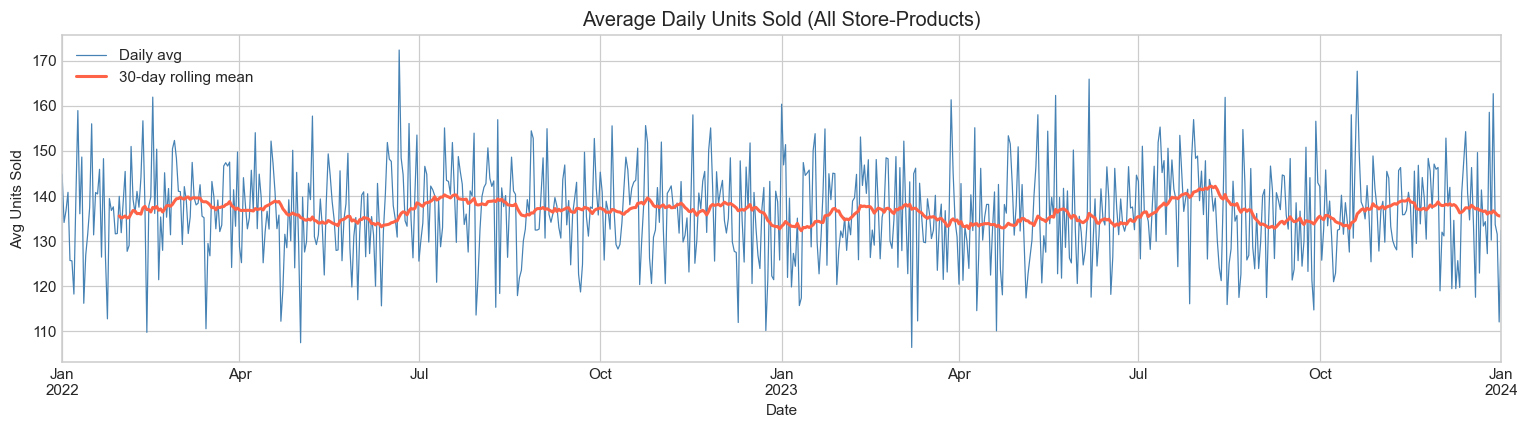

In [5]:
# ── Daily average sales over time ────────────────────────────────────────────
daily_avg = df.groupby("Date")["Units Sold"].mean()

fig, ax = plt.subplots(figsize=(14, 4))
daily_avg.plot(ax=ax, linewidth=0.8, color="steelblue", label="Daily avg")
daily_avg.rolling(30).mean().plot(ax=ax, linewidth=2, color="tomato", label="30-day rolling mean")
ax.set_title("Average Daily Units Sold (All Store-Products)", fontsize=13)
ax.set_xlabel("Date"); ax.set_ylabel("Avg Units Sold"); ax.legend()
plt.tight_layout()
plt.savefig(REPORTS_DIR / "eda_daily_avg_sales.png", dpi=110)
plt.show()


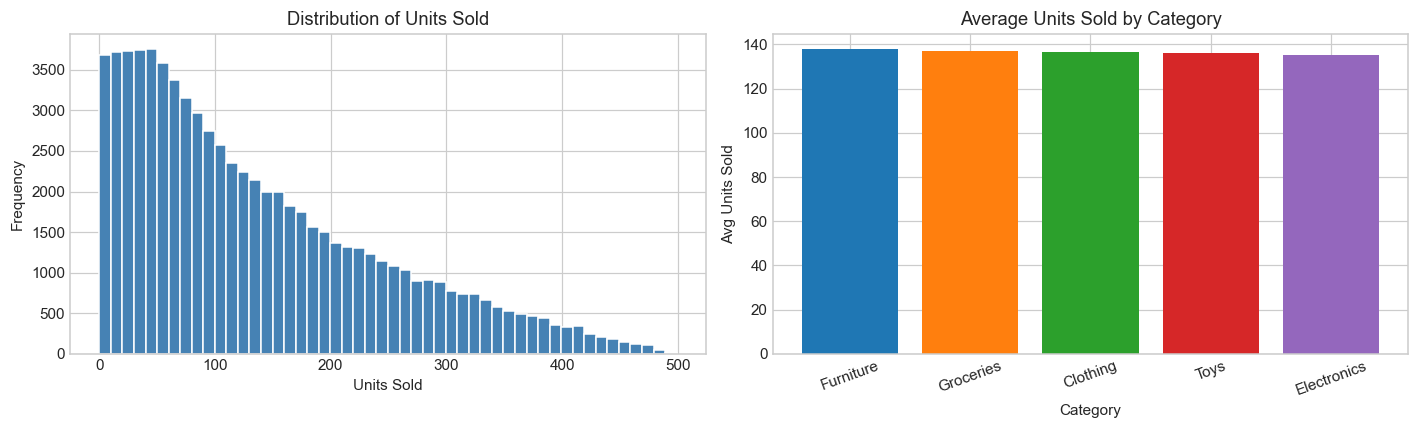

In [6]:
# ── Sales distribution & category breakdown ───────────────────────────────────
fig, axes = plt.subplots(1, 2, figsize=(13, 4))

axes[0].hist(df["Units Sold"], bins=50, color="steelblue", edgecolor="white")
axes[0].set_title("Distribution of Units Sold")
axes[0].set_xlabel("Units Sold"); axes[0].set_ylabel("Frequency")

cat_avg = df.groupby("Category")["Units Sold"].mean().sort_values(ascending=False)
axes[1].bar(cat_avg.index, cat_avg.values, color=sns.color_palette("tab10", len(cat_avg)))
axes[1].set_title("Average Units Sold by Category")
axes[1].set_xlabel("Category"); axes[1].set_ylabel("Avg Units Sold")
axes[1].tick_params(axis="x", rotation=20)

plt.tight_layout()
plt.savefig(REPORTS_DIR / "eda_sales_distribution.png", dpi=110)
plt.show()


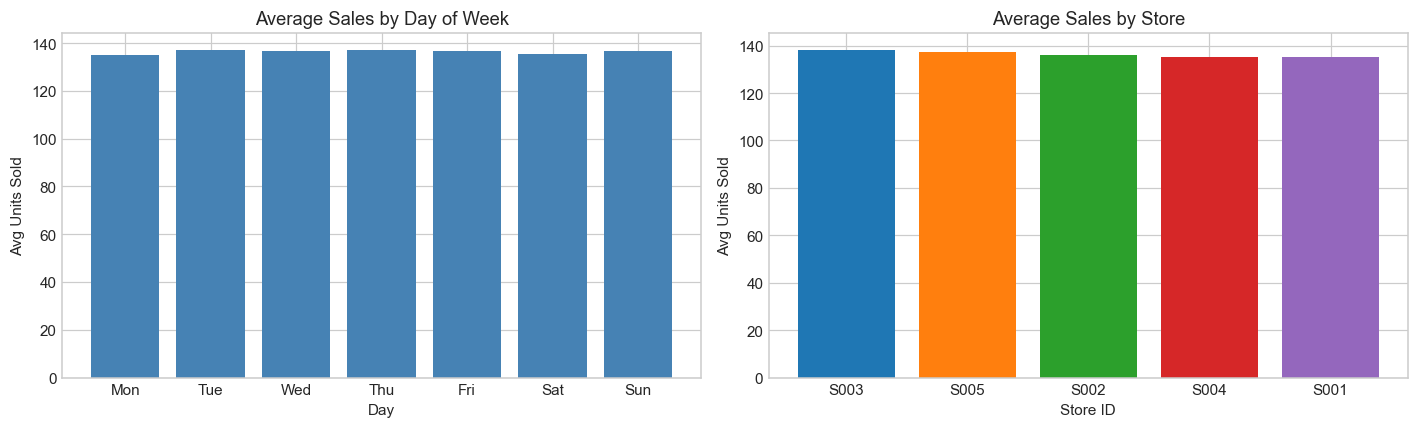

Corr(Price, Units Sold): 0.0011
Corr(Discount, Units Sold): 0.0026
Corr(Inventory Level, Units Sold): 0.5900
Corr(Competitor Pricing, Units Sold): 0.0013


In [7]:
# ── Day-of-week pattern & store-level comparison ─────────────────────────────
df["day_of_week"] = df["Date"].dt.dayofweek
dow_avg = df.groupby("day_of_week")["Units Sold"].mean()
dow_labels = ["Mon","Tue","Wed","Thu","Fri","Sat","Sun"]

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
axes[0].bar(dow_labels, dow_avg.values, color="steelblue")
axes[0].set_title("Average Sales by Day of Week")
axes[0].set_xlabel("Day"); axes[0].set_ylabel("Avg Units Sold")

store_avg = df.groupby("Store ID")["Units Sold"].mean().sort_values(ascending=False)
axes[1].bar(store_avg.index, store_avg.values, color=sns.color_palette("tab10", len(store_avg)))
axes[1].set_title("Average Sales by Store")
axes[1].set_xlabel("Store ID"); axes[1].set_ylabel("Avg Units Sold")

plt.tight_layout()
plt.savefig(REPORTS_DIR / "eda_dow_store.png", dpi=110)
plt.show()

# Correlation with Units Sold
for col in ["Price", "Discount", "Inventory Level", "Competitor Pricing"]:
    print(f"Corr({col}, Units Sold): {df[col].corr(df['Units Sold']):.4f}")


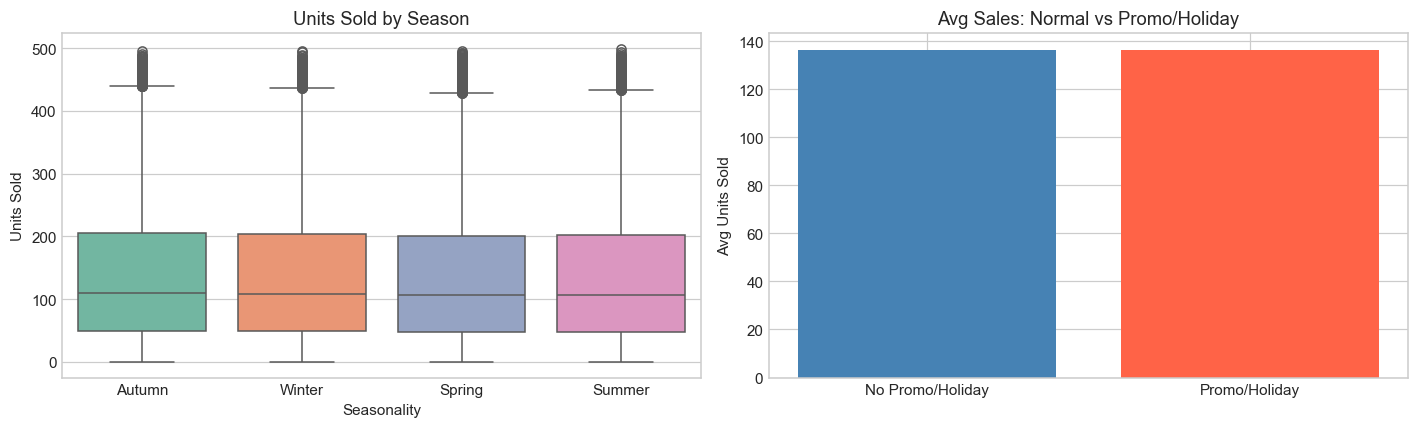

In [8]:
# ── Seasonality & promotions ──────────────────────────────────────────────────
fig, axes = plt.subplots(1, 2, figsize=(13, 4))

seas_order = df.groupby("Seasonality")["Units Sold"].mean().sort_values(ascending=False).index
sns.boxplot(x="Seasonality", y="Units Sold", data=df, palette="Set2", order=seas_order, ax=axes[0])
axes[0].set_title("Units Sold by Season")

promo_avg = df.groupby("Holiday/Promotion")["Units Sold"].mean()
axes[1].bar(["No Promo/Holiday", "Promo/Holiday"], promo_avg.values, color=["steelblue", "tomato"])
axes[1].set_title("Avg Sales: Normal vs Promo/Holiday")
axes[1].set_ylabel("Avg Units Sold")

plt.tight_layout()
plt.savefig(REPORTS_DIR / "eda_seasonality_promo.png", dpi=110)
plt.show()


## 4. Feature Engineering

> **No-leakage guarantee:** All lag and rolling features use `shift(1)` so day T only sees sales from day T-1 and earlier. Rolling windows are also shifted. Features are computed *within* each Store-Product group.

In [9]:
def build_features(df: pd.DataFrame) -> pd.DataFrame:
    df = df.copy()
    df = df.sort_values(["Store ID", "Product ID", "Date"]).reset_index(drop=True)

    # Calendar features (always available at prediction time)
    df["day_of_week"]  = df["Date"].dt.dayofweek
    df["day_of_month"] = df["Date"].dt.day
    df["month"]        = df["Date"].dt.month
    df["week_of_year"] = df["Date"].dt.isocalendar().week.astype(int)
    df["is_weekend"]   = (df["day_of_week"] >= 5).astype(int)
    df["quarter"]      = df["Date"].dt.quarter

    # Lag features per Store-Product (shift=1: use yesterday's sales for today)
    grp = df.groupby(["Store ID", "Product ID"])["Units Sold"]
    df["lag_1"]  = grp.shift(1)
    df["lag_7"]  = grp.shift(7)
    df["lag_14"] = grp.shift(14)

    # Rolling means (shift first, then roll — excludes current day)
    shifted = grp.shift(1)
    df["roll_mean_7"]  = shifted.transform(lambda x: x.rolling(7,  min_periods=3).mean())
    df["roll_mean_14"] = shifted.transform(lambda x: x.rolling(14, min_periods=7).mean())
    df["roll_mean_30"] = shifted.transform(lambda x: x.rolling(30, min_periods=14).mean())
    df["roll_std_7"]   = shifted.transform(lambda x: x.rolling(7,  min_periods=3).std())

    # Encode categorical identifiers (tree models handle these fine as integers)
    df["store_enc"]    = LabelEncoder().fit_transform(df["Store ID"])
    df["product_enc"]  = LabelEncoder().fit_transform(df["Product ID"])
    df["category_enc"] = LabelEncoder().fit_transform(df["Category"])
    df["region_enc"]   = LabelEncoder().fit_transform(df["Region"])
    df["weather_enc"]  = LabelEncoder().fit_transform(df["Weather Condition"])
    df["season_enc"]   = LabelEncoder().fit_transform(df["Seasonality"])

    return df


df = build_features(df)

FEATURE_COLS = [
    # Calendar
    "day_of_week", "day_of_month", "month", "week_of_year", "is_weekend", "quarter",
    # Lag / rolling
    "lag_1", "lag_7", "lag_14", "roll_mean_7", "roll_mean_14", "roll_mean_30", "roll_std_7",
    # Encoded categoricals
    "store_enc", "product_enc", "category_enc", "region_enc", "weather_enc", "season_enc",
    # Contextual numerics (known before the sale day)
    "Price", "Discount", "Inventory Level", "Holiday/Promotion", "Competitor Pricing",
]
TARGET = "Units Sold"

print(f"Total features: {len(FEATURE_COLS)}")
print(FEATURE_COLS)
df[FEATURE_COLS + [TARGET]].head(3)


Total features: 24
['day_of_week', 'day_of_month', 'month', 'week_of_year', 'is_weekend', 'quarter', 'lag_1', 'lag_7', 'lag_14', 'roll_mean_7', 'roll_mean_14', 'roll_mean_30', 'roll_std_7', 'store_enc', 'product_enc', 'category_enc', 'region_enc', 'weather_enc', 'season_enc', 'Price', 'Discount', 'Inventory Level', 'Holiday/Promotion', 'Competitor Pricing']


,day_of_week,day_of_month,month,week_of_year,is_weekend,quarter,lag_1,lag_7,lag_14,roll_mean_7,...,category_enc,region_enc,weather_enc,season_enc,Price,Discount,Inventory Level,Holiday/Promotion,Competitor Pricing,Units Sold
0,5,1,1,52,1,1,NaN,NaN,NaN,NaN,...,3,1,1,0,33.50,20,231,0,29.69,127
1,6,2,1,52,1,1,127.0,NaN,NaN,NaN,...,3,3,0,1,27.95,10,116,0,30.89,81
2,0,3,1,1,0,1,81.0,NaN,NaN,NaN,...,1,3,1,3,62.70,20,154,0,58.22,5


## 5. Temporal Train / Validation / Test Split

Split is by **date** (not random rows). 70% train / 15% val / 15% test.

In [10]:
unique_dates = sorted(df["Date"].unique())
n = len(unique_dates)

train_cutoff = unique_dates[int(n * 0.70)]
val_cutoff   = unique_dates[int(n * 0.85)]

df_train = df[df["Date"] <  train_cutoff].copy()
df_val   = df[(df["Date"] >= train_cutoff) & (df["Date"] < val_cutoff)].copy()
df_test  = df[df["Date"] >= val_cutoff].copy()

print(f"Total unique dates : {n}")
print(f"Train : {df_train['Date'].min().date()} -> {df_train['Date'].max().date()}  {len(df_train):,} rows")
print(f"Val   : {df_val['Date'].min().date()}   -> {df_val['Date'].max().date()}  {len(df_val):,} rows")
print(f"Test  : {df_test['Date'].min().date()}  -> {df_test['Date'].max().date()}  {len(df_test):,} rows")


Total unique dates : 731
Train : 2022-01-01 -> 2023-05-26  51,100 rows
Val   : 2023-05-27   -> 2023-09-13  11,000 rows
Test  : 2023-09-14  -> 2024-01-01  11,000 rows


In [11]:
# Drop rows where minimum lag features are NaN
# (first ~7 days of each series can't compute all rolling windows)
MIN_LAGS = ["lag_1", "lag_7", "roll_mean_7"]

df_train_ml = df_train.dropna(subset=MIN_LAGS)
df_val_ml   = df_val.dropna(subset=MIN_LAGS)
df_test_ml  = df_test.dropna(subset=MIN_LAGS)

print(f"After NaN-drop: train={len(df_train_ml):,}, val={len(df_val_ml):,}, test={len(df_test_ml):,}")

X_train = df_train_ml[FEATURE_COLS]; y_train = df_train_ml[TARGET]
X_val   = df_val_ml[FEATURE_COLS];   y_val   = df_val_ml[TARGET]
X_test  = df_test_ml[FEATURE_COLS];  y_test  = df_test_ml[TARGET]

# Median fill for models that don't handle NaN (LinearRegression, RandomForest, XGBoost)
col_medians     = X_train.median()
X_train_filled  = X_train.fillna(col_medians)
X_val_filled    = X_val.fillna(col_medians)
X_test_filled   = X_test.fillna(col_medians)

print(f"X_train: {X_train_filled.shape}  X_val: {X_val_filled.shape}  X_test: {X_test_filled.shape}")


After NaN-drop: train=50,400, val=11,000, test=11,000
X_train: (50400, 24)  X_val: (11000, 24)  X_test: (11000, 24)


## 6. Baseline Models

In [12]:
def compute_metrics(y_true, y_pred, name="Model"):
    mae  = mean_absolute_error(y_true, y_pred)
    rmse = math.sqrt(mean_squared_error(y_true, y_pred))
    denom = np.abs(np.asarray(y_true)).sum()
    wape = 100 * np.abs(np.asarray(y_true) - np.asarray(y_pred)).sum() / denom if denom > 0 else float("nan")
    return {"Model": name, "MAE": round(mae, 3), "RMSE": round(rmse, 3), "WAPE(%)": round(wape, 3)}


results = []   # collect all model scores

# Naive: predict yesterday's sales
val_naive  = compute_metrics(df_val_ml[TARGET],  df_val_ml["lag_1"].fillna(0),  "Naive (lag-1)")
test_naive = compute_metrics(df_test_ml[TARGET], df_test_ml["lag_1"].fillna(0), "Naive (lag-1)")
results.append({**val_naive,  "Split": "Val",  "Train_s": 0})
results.append({**test_naive, "Split": "Test", "Train_s": 0})
print("Naive — Val :", val_naive)
print("Naive — Test:", test_naive)

# Seasonal naive: predict same weekday last week
val_snv   = compute_metrics(df_val_ml[TARGET],  df_val_ml["lag_7"].fillna(0),  "Seasonal Naive (lag-7)")
test_snv  = compute_metrics(df_test_ml[TARGET], df_test_ml["lag_7"].fillna(0), "Seasonal Naive (lag-7)")
results.append({**val_snv,  "Split": "Val",  "Train_s": 0})
results.append({**test_snv, "Split": "Test", "Train_s": 0})
print("Seasonal Naive — Val :", val_snv)
print("Seasonal Naive — Test:", test_snv)


Naive — Val : {'Model': 'Naive (lag-1)', 'MAE': 121.771, 'RMSE': 156.137, 'WAPE(%)': np.float64(89.074)}
Naive — Test: {'Model': 'Naive (lag-1)', 'MAE': 119.342, 'RMSE': 152.726, 'WAPE(%)': np.float64(87.471)}
Seasonal Naive — Val : {'Model': 'Seasonal Naive (lag-7)', 'MAE': 120.444, 'RMSE': 154.907, 'WAPE(%)': np.float64(88.103)}
Seasonal Naive — Test: {'Model': 'Seasonal Naive (lag-7)', 'MAE': 118.31, 'RMSE': 151.735, 'WAPE(%)': np.float64(86.715)}


## 7. Train ML Models

In [13]:
# ── 7.1 Linear Regression ─────────────────────────────────────────────────────
print("Training Linear Regression...")
t0 = time.time()
lr = LinearRegression()
lr.fit(X_train_filled, y_train)
lr_time = round(time.time() - t0, 2)

lr_val  = compute_metrics(y_val,  lr.predict(X_val_filled),  "Linear Regression")
lr_test = compute_metrics(y_test, lr.predict(X_test_filled), "Linear Regression")
results += [{**lr_val, "Split":"Val","Train_s":lr_time}, {**lr_test, "Split":"Test","Train_s":lr_time}]
print(f"  {lr_time}s | Val: {lr_val} | Test: {lr_test}")


Training Linear Regression...
  0.03s | Val: {'Model': 'Linear Regression', 'MAE': 68.745, 'RMSE': 88.016, 'WAPE(%)': np.float64(50.286)} | Test: {'Model': 'Linear Regression', 'MAE': 68.777, 'RMSE': 87.801, 'WAPE(%)': np.float64(50.41)}


In [14]:
# ── 7.2 Random Forest ─────────────────────────────────────────────────────────
print("Training Random Forest (200 trees, max_depth=12)...")
t0 = time.time()
rf = RandomForestRegressor(
    n_estimators=200, max_depth=12, min_samples_leaf=5,
    n_jobs=-1, random_state=RANDOM_STATE)
rf.fit(X_train_filled, y_train)
rf_time = round(time.time() - t0, 2)

rf_val  = compute_metrics(y_val,  rf.predict(X_val_filled),  "Random Forest")
rf_test = compute_metrics(y_test, rf.predict(X_test_filled), "Random Forest")
results += [{**rf_val, "Split":"Val","Train_s":rf_time}, {**rf_test, "Split":"Test","Train_s":rf_time}]
print(f"  {rf_time}s | Val: {rf_val} | Test: {rf_test}")


Training Random Forest (200 trees, max_depth=12)...


  14.28s | Val: {'Model': 'Random Forest', 'MAE': 68.841, 'RMSE': 88.301, 'WAPE(%)': np.float64(50.357)} | Test: {'Model': 'Random Forest', 'MAE': 69.028, 'RMSE': 88.225, 'WAPE(%)': np.float64(50.594)}


In [15]:
# ── 7.3 HistGradientBoosting (handles NaN natively) ──────────────────────────
print("Training HistGradientBoostingRegressor (300 iters)...")
t0 = time.time()
hgb = HistGradientBoostingRegressor(
    max_iter=300, learning_rate=0.05, max_depth=6,
    min_samples_leaf=20, random_state=RANDOM_STATE)
hgb.fit(X_train, y_train)   # use un-filled X — HGB handles NaN internally
hgb_time = round(time.time() - t0, 2)

hgb_val  = compute_metrics(y_val,  hgb.predict(X_val),  "HistGradientBoosting")
hgb_test = compute_metrics(y_test, hgb.predict(X_test), "HistGradientBoosting")
results += [{**hgb_val, "Split":"Val","Train_s":hgb_time}, {**hgb_test, "Split":"Test","Train_s":hgb_time}]
print(f"  {hgb_time}s | Val: {hgb_val} | Test: {hgb_test}")


Training HistGradientBoostingRegressor (300 iters)...


  0.4s | Val: {'Model': 'HistGradientBoosting', 'MAE': 68.911, 'RMSE': 88.312, 'WAPE(%)': np.float64(50.408)} | Test: {'Model': 'HistGradientBoosting', 'MAE': 68.907, 'RMSE': 88.084, 'WAPE(%)': np.float64(50.505)}


In [16]:
# ── 7.4 XGBoost (CPU hist method) ────────────────────────────────────────────
print("Training XGBoost (400 trees, hist, CPU)...")
t0 = time.time()
xgb_model = XGBRegressor(
    n_estimators=400, learning_rate=0.05, max_depth=6,
    subsample=0.8, colsample_bytree=0.8,
    tree_method="hist", device="cpu",
    random_state=RANDOM_STATE, n_jobs=-1, verbosity=0)
xgb_model.fit(X_train_filled, y_train,
              eval_set=[(X_val_filled, y_val)], verbose=False)
xgb_time = round(time.time() - t0, 2)

xgb_val  = compute_metrics(y_val,  xgb_model.predict(X_val_filled),  "XGBoost")
xgb_test = compute_metrics(y_test, xgb_model.predict(X_test_filled), "XGBoost")
results += [{**xgb_val, "Split":"Val","Train_s":xgb_time}, {**xgb_test, "Split":"Test","Train_s":xgb_time}]
print(f"  {xgb_time}s | Val: {xgb_val} | Test: {xgb_test}")


Training XGBoost (400 trees, hist, CPU)...


  1.57s | Val: {'Model': 'XGBoost', 'MAE': 69.313, 'RMSE': 89.17, 'WAPE(%)': np.float64(50.702)} | Test: {'Model': 'XGBoost', 'MAE': 69.5, 'RMSE': 88.988, 'WAPE(%)': np.float64(50.94)}


## 8. Evaluate & Compare All Models

In [17]:
results_df = pd.DataFrame(results)

val_tbl  = results_df[results_df["Split"]=="Val"].sort_values("MAE").reset_index(drop=True)
test_tbl = results_df[results_df["Split"]=="Test"].reset_index(drop=True)

print("=== VALIDATION RESULTS (sorted by MAE) ===")
display(val_tbl[["Model","MAE","RMSE","WAPE(%)","Train_s"]])
print()
print("=== TEST RESULTS ===")
display(test_tbl[["Model","MAE","RMSE","WAPE(%)"]])


=== VALIDATION RESULTS (sorted by MAE) ===


,Model,MAE,RMSE,WAPE(%),Train_s
0,Linear Regression,68.745,88.016,50.286,0.03
1,Random Forest,68.841,88.301,50.357,14.28
2,HistGradientBoosting,68.911,88.312,50.408,0.40
3,XGBoost,69.313,89.170,50.702,1.57
4,Seasonal Naive (lag-7),120.444,154.907,88.103,0.00
5,Naive (lag-1),121.771,156.137,89.074,0.00



=== TEST RESULTS ===


,Model,MAE,RMSE,WAPE(%)
0,Naive (lag-1),119.342,152.726,87.471
1,Seasonal Naive (lag-7),118.310,151.735,86.715
2,Linear Regression,68.777,87.801,50.410
3,Random Forest,69.028,88.225,50.594
4,HistGradientBoosting,68.907,88.084,50.505
5,XGBoost,69.500,88.988,50.940


Saved model_comparison.csv -> C:\Projects\Inventory-compass\backend\reports


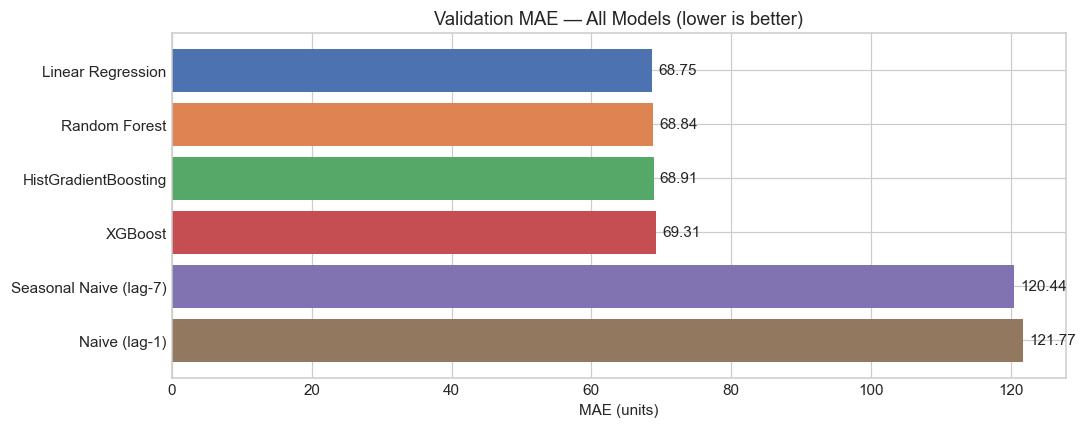

In [18]:
results_df.to_csv(REPORTS_DIR / "model_comparison.csv", index=False)
print(f"Saved model_comparison.csv -> {REPORTS_DIR}")

# Validation MAE bar chart
fig, ax = plt.subplots(figsize=(10, 4))
plot_df = val_tbl[["Model","MAE"]].copy()
bars = ax.barh(plot_df["Model"], plot_df["MAE"],
               color=["#4C72B0","#DD8452","#55A868","#C44E52","#8172B2","#937860"][:len(plot_df)])
ax.bar_label(bars, fmt="%.2f", padding=4)
ax.set_xlabel("MAE (units)")
ax.set_title("Validation MAE — All Models (lower is better)")
ax.invert_yaxis()
plt.tight_layout()
plt.savefig(REPORTS_DIR / "model_comparison_mae.png", dpi=110)
plt.show()


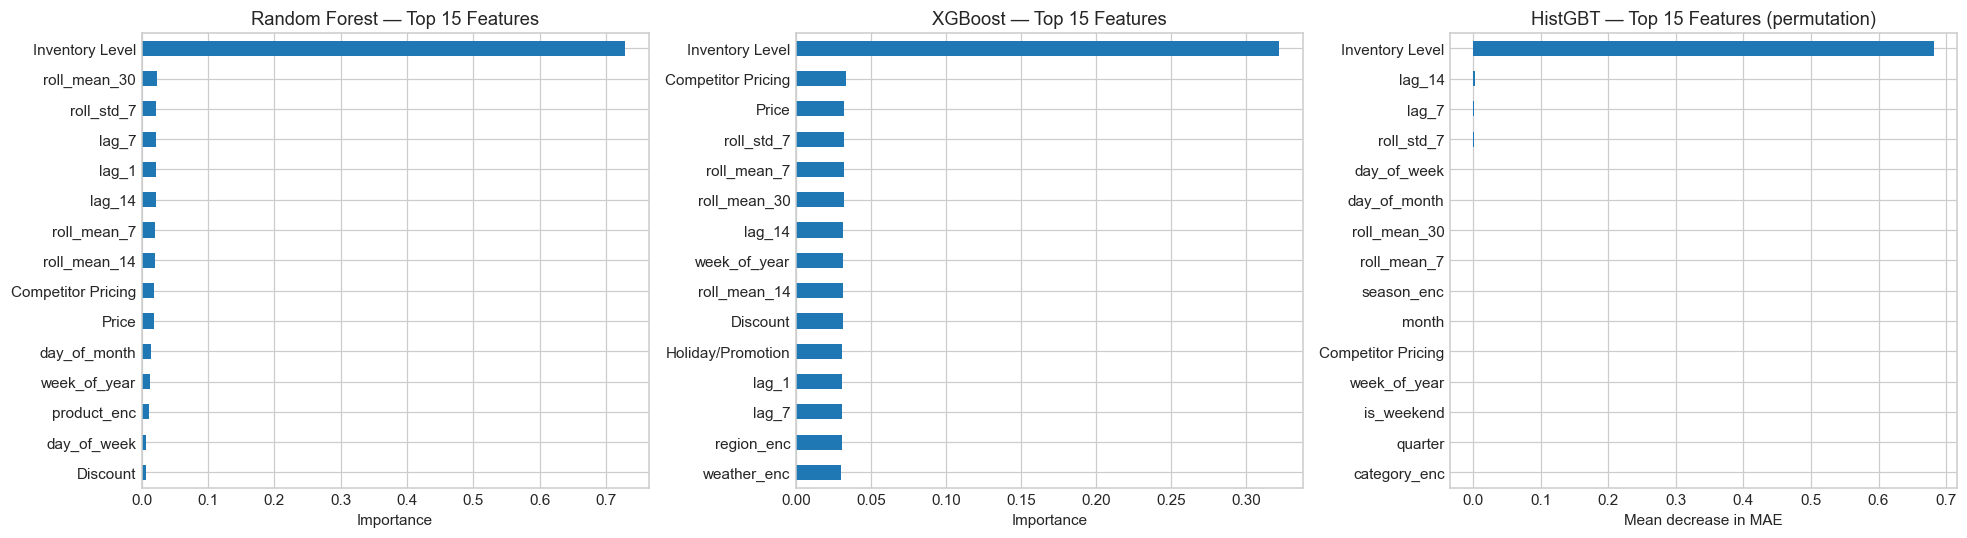

In [19]:
# Feature importances for tree models
# Note: HistGradientBoostingRegressor does not expose feature_importances_
# directly, so we use permutation importance on a small validation sample.
from sklearn.inspection import permutation_importance

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# --- Random Forest & XGBoost: native feature_importances_ ---
for ax, model, name in zip(axes[:2], [rf, xgb_model], ["Random Forest", "XGBoost"]):
    imp = pd.Series(model.feature_importances_, index=FEATURE_COLS).sort_values(ascending=False).head(15)
    imp.plot.barh(ax=ax)
    ax.invert_yaxis()
    ax.set_title(f"{name} — Top 15 Features")
    ax.set_xlabel("Importance")

# --- HistGBT: permutation importance on val sample (fast subset) ---
sample_idx = np.random.choice(len(X_val), min(2000, len(X_val)), replace=False)
perm = permutation_importance(
    hgb, X_val.iloc[sample_idx], y_val.iloc[sample_idx],
    n_repeats=5, random_state=RANDOM_STATE, n_jobs=-1)
perm_imp = pd.Series(perm.importances_mean, index=FEATURE_COLS).sort_values(ascending=False).head(15)
perm_imp.plot.barh(ax=axes[2])
axes[2].invert_yaxis()
axes[2].set_title("HistGBT — Top 15 Features (permutation)")
axes[2].set_xlabel("Mean decrease in MAE")

plt.tight_layout()
plt.savefig(REPORTS_DIR / "feature_importances.png", dpi=110)
plt.show()


Best model (Val MAE): Linear Regression


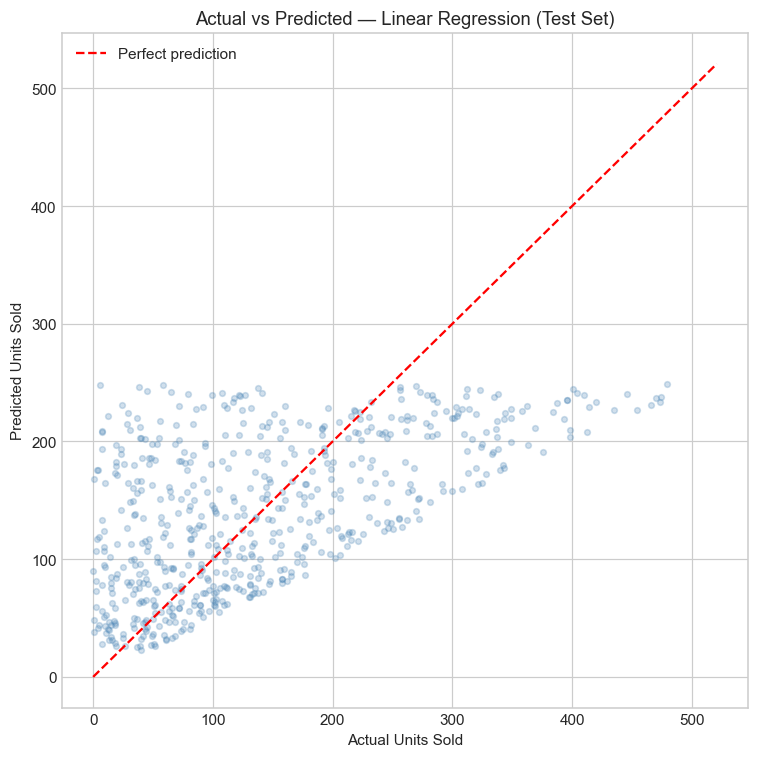

In [20]:
# Pick best model by validation MAE
ml_models_val = val_tbl[val_tbl["Model"].isin(["Linear Regression","Random Forest","HistGradientBoosting","XGBoost"])]
best_model_name = ml_models_val.iloc[0]["Model"]
print(f"Best model (Val MAE): {best_model_name}")

model_map = {
    "Linear Regression":   (lr,        X_test_filled),
    "Random Forest":        (rf,        X_test_filled),
    "HistGradientBoosting": (hgb,       X_test),
    "XGBoost":              (xgb_model, X_test_filled),
}
best_obj, best_Xt = model_map[best_model_name]
y_pred_best = best_obj.predict(best_Xt)

idx = np.random.choice(len(y_test), min(600, len(y_test)), replace=False)
fig, ax = plt.subplots(figsize=(7, 7))
ax.scatter(np.array(y_test)[idx], y_pred_best[idx], alpha=0.25, s=14, color="steelblue")
lim = max(np.array(y_test).max(), y_pred_best.max()) * 1.05
ax.plot([0, lim], [0, lim], "r--", lw=1.5, label="Perfect prediction")
ax.set_xlabel("Actual Units Sold"); ax.set_ylabel("Predicted Units Sold")
ax.set_title(f"Actual vs Predicted — {best_model_name} (Test Set)")
ax.legend()
plt.tight_layout()
plt.savefig(REPORTS_DIR / "actual_vs_predicted.png", dpi=110)
plt.show()


## 9. Save Best Model + Metadata

In [21]:
# Gather best model's test metrics
best_test_row = test_tbl[test_tbl["Model"] == best_model_name].iloc[0]
best_val_row  = ml_models_val.iloc[0]

metadata = {
    "model_type":          best_model_name,
    "target_variable":     TARGET,
    "forecast_horizon":    "1 day ahead (t+1)",
    "feature_names":       FEATURE_COLS,
    "n_features":          len(FEATURE_COLS),
    "training_cutoff_date": str(pd.Timestamp(train_cutoff).date()),
    "val_cutoff_date":      str(pd.Timestamp(val_cutoff).date()),
    "train_rows":  int(len(df_train_ml)),
    "val_rows":    int(len(df_val_ml)),
    "test_rows":   int(len(df_test_ml)),
    "val_mae":   float(best_val_row["MAE"]),
    "val_rmse":  float(best_val_row["RMSE"]),
    "val_wape":  float(best_val_row["WAPE(%)"]),
    "test_mae":  float(best_test_row["MAE"]),
    "test_rmse": float(best_test_row["RMSE"]),
    "test_wape": float(best_test_row["WAPE(%)"]),
    "col_medians":    col_medians.to_dict(),
    "random_state":   RANDOM_STATE,
    "dataset":        "retail_store_inventory.csv",
    "dataset_note":   "Synthetic retail dataset. Results may not generalise to real-world data.",
    "trained_at":     datetime.now().isoformat(),
    "excluded_features": ["Demand Forecast — unknown provenance, negative values present"],
}

model_fname = f"best_model_{best_model_name.lower().replace(' ','_')}.joblib"
model_path  = MODELS_DIR / model_fname
meta_path   = MODELS_DIR / "model_metadata.json"

joblib.dump(best_obj, model_path, compress=3)
meta_path.write_text(json.dumps(metadata, indent=2), encoding="utf-8")

print(f"Model saved   : {model_path}")
print(f"Metadata saved: {meta_path}")
print(f"\n=== FINAL TEST METRICS ({best_model_name}) ===")
print(f"  MAE     : {metadata['test_mae']}")
print(f"  RMSE    : {metadata['test_rmse']}")
print(f"  WAPE(%) : {metadata['test_wape']}")


Model saved   : C:\Projects\Inventory-compass\backend\models\best_model_linear_regression.joblib
Metadata saved: C:\Projects\Inventory-compass\backend\models\model_metadata.json

=== FINAL TEST METRICS (Linear Regression) ===
  MAE     : 68.777
  RMSE    : 87.801
  WAPE(%) : 50.41


In [22]:
# Reload and verify predictions are reproducible
loaded_model = joblib.load(model_path)

if best_model_name == "HistGradientBoosting":
    y_check = loaded_model.predict(X_test.iloc[:5])
else:
    y_check = loaded_model.predict(X_test_filled.iloc[:5])

print("Model reload — first 5 predictions:", y_check.round(2))
print("Actual values                       :", y_test.iloc[:5].values)


Model reload — first 5 predictions: [122.11  37.29 245.07 225.18 244.32]
Actual values                       : [ 34  18 122 139 262]


## 10. Download Model

The cells below let you download the saved model file from inside the notebook.  
The model is also saved at `backend/models/` and can be copied from there directly.


In [23]:
# Download the model .joblib file
try:
    from IPython.display import FileLink, display as ipy_display
    print("Click the link to download the model:")
    ipy_display(FileLink(str(model_path), result_html_prefix="Download model: "))
except Exception:
    print(f"Model file location: {model_path}")


Click the link to download the model:


C:\Projects\Inventory-compass\backend\models\best_model_linear_regression.joblib

In [24]:
# Create a zip bundle: model + metadata  (convenient single-file download)
zip_path = MODELS_DIR / "inventory_compass_model_bundle.zip"
with zipfile.ZipFile(zip_path, "w", zipfile.ZIP_DEFLATED) as zf:
    zf.write(model_path, model_path.name)
    zf.write(meta_path,  meta_path.name)

size_kb = zip_path.stat().st_size / 1024
print(f"Bundle saved: {zip_path}  ({size_kb:.1f} KB)")

try:
    from IPython.display import FileLink, display as ipy_display
    ipy_display(FileLink(str(zip_path), result_html_prefix="Download bundle: "))
except Exception:
    print(f"Zip location: {zip_path}")


Bundle saved: C:\Projects\Inventory-compass\backend\models\inventory_compass_model_bundle.zip  (2.1 KB)


C:\Projects\Inventory-compass\backend\models\inventory_compass_model_bundle.zip

---
## Summary

| Step | Output |
|------|--------|
| Raw data loaded & cleaned | `backend/data/processed/clean_inventory.csv` |
| EDA charts | `backend/reports/eda_*.png` |
| Model comparison table | `backend/reports/model_comparison.csv` |
| MAE bar chart | `backend/reports/model_comparison_mae.png` |
| Feature importance chart | `backend/reports/feature_importances.png` |
| Actual vs Predicted chart | `backend/reports/actual_vs_predicted.png` |
| Best model saved | `backend/models/best_model_*.joblib` |
| Model metadata | `backend/models/model_metadata.json` |
| Download bundle | `backend/models/inventory_compass_model_bundle.zip` |

**To reproduce:** activate `.venv`, open `backend/notebooks/inventory_compass_pipeline.ipynb`, run all cells top to bottom.
